<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# <font color="#14532D">Modelo SIR: Ajuste de parámetros del modelo SIR</font>

**Instrucciones:** Elaborar en un cuaderno de Jupyter Notebook en lenguaje Python el código para ajustar los parámetros del modelo SIR mediante MCMC, siguiendo los artículos proporcionados.

### <font color="#689F38">Objetivo</font>

Estimar los parámetros $a$ (tasa de transmisión) y $b$ (tasa promedio de recuperación) del modelo SIR que mejor describen el brote de influenza en un internado de $N=763$ estudiantes, utilizando la función $\chi^2$ para evaluar el ajuste y el algoritmo Metropolis-Hastings (MCMC) para estimar los parámetros y cuantificar su incertidumbre.



## <font color="#2E7D32">1. Modelo SIR</font>

El modelo SIR describe la propagación de una enfermedad infecciosa mediante tres ecuaciones diferenciales ordinarias no lineales. La población se divide en tres grupos: susceptibles $S(t)$, infectados $I(t)$ y removidos $R(t)$.

El sistema está dado por:

$$
\begin{aligned}
\frac{dS}{dt} &= -aSI,\\[6pt]
\frac{dI}{dt} &= aSI-bI,\\[6pt]
\frac{dR}{dt} &= bI.
\end{aligned}
$$

Donde:

- $a$: tasa de transmisión.
- $b$: tasa promedio de recuperación.

La población total se mantiene constante:

$$
N=S(t)+I(t)+R(t),
$$

por lo que:

$$
\frac{dN}{dt}=
\frac{dS}{dt}+\frac{dI}{dt}+\frac{dR}{dt}=0.
$$

Como el sistema no tiene una solución analítica explícita, lo resolveremos numéricamente para obtener el comportamiento de los infectados y posteriormente ajustar los parámetros $a$ y $b$.



## <font color="#2E7D32">2. Planteamiento del problema</font>

En 1978 se registró un brote de influenza en un internado con 763 estudiantes. A partir del número de infectados observado durante 15 días, buscamos determinar los parámetros $a$ y $b$ que permiten aproximar el comportamiento de la epidemia.

Se trata de un **problema inverso**, ya que conocemos los datos observados y queremos determinar los parámetros del modelo que mejor los describen.

### <font color="#689F38">2.1. Datos observados</font>

La siguiente tabla muestra los datos del brote de influenza:

| $t$ (días) | $I(t)$ | $t$ (días) | $I(t)$ | $t$ (días) | $I(t)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 0 | 1 | 5 | 222 | 10 | 125 |
| 1 | 3 | 6 | 294 | 11 | 69 |
| 2 | 6 | 7 | 258 | 12 | 27 |
| 3 | 25 | 8 | 237 | 13 | 11 |
| 4 | 73 | 9 | 191 | 14 | 4 |

*Fuente: Tabla 1 de The inverse problem of a dynamical system solved with genetic algorithms.*

La población total es $N=763$. Considerando que inicialmente hay un estudiante infectado y ninguno removido, tenemos:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0.
$$

Estos datos serán la base para comparar la solución numérica del modelo SIR con las observaciones.



### <font color="#689F38">2.2. Representación de los datos</font>

Primero registramos los datos en Python y los graficamos para observar cómo cambia el número de infectados durante el brote.


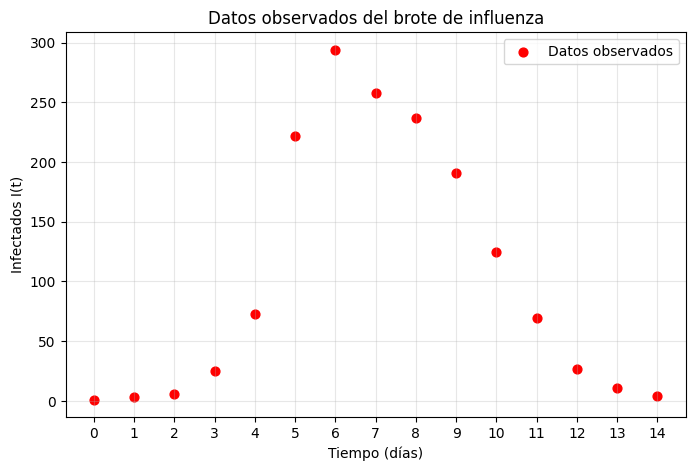

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Población total del internado
N = 763

# Días y número de infectados observados
t = np.arange(15)
I_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258,
                  237, 191, 125, 69, 27, 11, 4])

# Condiciones iniciales del modelo SIR
S0, I0, R0 = 762, 1, 0

# Gráfica de los datos observados
plt.figure(figsize=(8, 5))
plt.scatter(t, I_obs, color="red", s=40,
            label="Datos observados")

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Datos observados del brote de influenza")
plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.show()



### <font color="#689F38">Observación</font>

El número de infectados aumenta hasta alcanzar un máximo de 294 estudiantes en el día 6 y después disminuye hasta llegar a 4 infectados en el día 14.

Buscaremos reproducir este comportamiento mediante la solución numérica del modelo SIR.



## <font color="#2E7D32">3. Solución numérica del modelo SIR</font>

Para obtener la evolución de $S(t)$, $I(t)$ y $R(t)$, utilizaremos `solve_ivp` de Python, que permite resolver numéricamente el sistema de ecuaciones diferenciales.

Primero definimos el modelo SIR y después una función que calcule su solución para diferentes valores de $a$ y $b$. De esta manera, podremos comparar los infectados calculados con los datos observados durante el ajuste.


In [3]:

# Definimos las ecuaciones diferenciales del modelo SIR
def SIR(t, y, a, b):

    S, I, R = y

    # Cambio de susceptibles, infectados y removidos
    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return [dS, dI, dR]


# Resolvemos el sistema para los parámetros a y b
def resolver_SIR(a, b):

    # Condiciones iniciales
    y0 = [S0, I0, R0]

    # Calculamos la solución en los días observados
    solucion = solve_ivp(
        SIR, (t[0], t[-1]), y0,
        args=(a, b),
        t_eval=t,
        rtol=1e-6,
        atol=1e-8
    )

    # Comprobamos que la solución se haya calculado
    if not solucion.success:
        raise RuntimeError("No se pudo resolver el modelo SIR.")

    return solucion.y



### <font color="#689F38">3.1. Comparación inicial</font>

Para comprobar la solución numérica, utilizaremos los parámetros reportados mediante algoritmos genéticos:

$$
a=0.00205,\qquad b=0.43552.
$$

Calcularemos la solución del modelo SIR con estos valores y la compararemos con los datos observados. Para obtener una curva más suave, evaluaremos el sistema en un mayor número de puntos de tiempo.


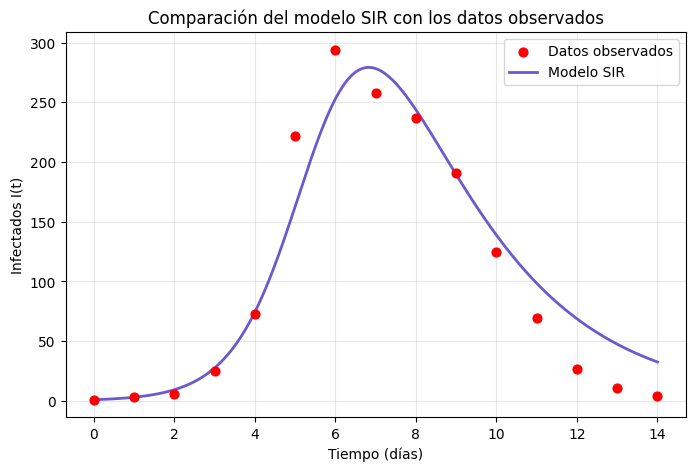

In [4]:

# Parámetros obtenidos mediante el algoritmo genético
a = 0.00205
b = 0.43552

# Puntos de tiempo para representar una curva suave
t_suave = np.linspace(0, 14, 300)

# Calculamos la solución del modelo SIR
solucion = solve_ivp(
    SIR, (0, 14), [S0, I0, R0],
    args=(a, b),
    t_eval=t_suave,
    rtol=1e-6,
    atol=1e-8
)

# Obtenemos los infectados calculados
I_suave = solucion.y[1]

# Comparamos la solución con los datos observados
plt.figure(figsize=(8, 5))

plt.scatter(t, I_obs, color="red", s=40,
            label="Datos observados", zorder=3)

plt.plot(t_suave, I_suave, color="slateblue",
         linewidth=2, label="Modelo SIR")

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Comparación del modelo SIR con los datos observados")
plt.xticks(np.arange(0, 15, 2))
plt.grid(alpha=0.3)
plt.legend()
plt.show()



### <font color="#689F38">Observación</font>

La solución numérica reproduce el aumento y la disminución de los infectados, aunque presenta diferencias respecto a los datos observados.

Para medir estas diferencias y encontrar los parámetros que produzcan un mejor ajuste, utilizaremos la función chi-cuadrada ($\chi^2$).



## <font color="#2E7D32">4. Función chi-cuadrada ($\chi^2$)</font>

La función chi-cuadrada permite medir las diferencias entre los datos observados y los valores calculados por un modelo, considerando la incertidumbre de las observaciones.

Su expresión general es:

$$
\chi^2=\sum_{i,j}
(D_i-y_i(x_i|\theta))Q_{ij}(D_j-y_j(x_j|\theta)),
$$

donde:

- $D_i$: datos observados.
- $y_i(x_i|\theta)$: valores calculados por el modelo.
- $\theta$: parámetros que se desean estimar.
- $Q$: inversa de la matriz de covarianza de los datos.

### <font color="#689F38">4.1. Aplicación al modelo SIR</font>

En nuestro problema, los parámetros son $\theta=(a,b)$ y los datos corresponden al número de infectados $I(t)$.

Si consideramos errores independientes, la función se expresa como:

$$
\chi^2(a,b)=\sum_{i=0}^{14}
\frac{[I_{\mathrm{obs}}(t_i)-I_{\mathrm{mod}}(t_i;a,b)]^2}{\sigma_i^2}.
$$

Para realizar el ajuste, supondremos que todas las observaciones tienen la misma desviación estándar, $\sigma_i=1$. Por lo tanto:

$$
\boxed{
\chi^2(a,b)=\sum_{i=0}^{14}
[I_{\mathrm{obs}}(t_i)-I_{\mathrm{mod}}(t_i;a,b)]^2
}
$$

**Interpretación:** un valor menor de $\chi^2$ indica que la solución del modelo se encuentra más cerca de los datos observados.

La elección de $\sigma_i=1$ permite dar el mismo peso a todos los datos. Posteriormente, la incertidumbre de los parámetros dependerá de este supuesto.



Para calcular $\chi^2$, utilizaremos la función `resolver_SIR(a, b)` que definimos anteriormente.

Primero obtenemos el número de infectados calculado por el modelo y después sumamos las diferencias al cuadrado respecto a los datos observados.


In [5]:

# Función para calcular chi-cuadrada
def chi2(a, b):

    # Obtenemos la solución del modelo SIR
    S, I, R = resolver_SIR(a, b)

    # Calculamos las diferencias con los datos observados
    error = I_obs - I

    # Sumamos los errores al cuadrado
    return np.sum(error**2)



### <font color="#689F38">4.2. Evaluación del ajuste</font>

Para comprobar la función $\chi^2$, utilizaremos los siguientes parámetros de referencia:

| Referencia | $a$ | $b$ |
|:---|---:|---:|
| Murray | 0.00218 | 0.4485 |
| Algoritmo genético (GA) | 0.00205 | 0.43552 |

Calcularemos el error de cada par utilizando la misma función $\chi^2$. Estos resultados servirán para comparar posteriormente los parámetros obtenidos mediante MCMC.


In [6]:

# Parámetros de referencia
a1, b1 = 0.00218, 0.4485    # Murray
a2, b2 = 0.00205, 0.43552   # Algoritmo genético

# Calculamos chi-cuadrada para cada par
chi2_1 = chi2(a1, b1)
chi2_2 = chi2(a2, b2)

# Mostramos los resultados
print(f"Chi-cuadrada de Murray: {chi2_1:.4f}")
print(f"Chi-cuadrada del algoritmo genético: {chi2_2:.4f}")


Chi-cuadrada de Murray: 4526.4889
Chi-cuadrada del algoritmo genético: 10644.0261



### <font color="#689F38">Observación</font>

Los valores de $\chi^2$ permiten comparar qué tan cerca están las soluciones de Murray y del algoritmo genético de los datos observados. El menor valor corresponde al par que presenta menos diferencias según esta medida de error.

Ahora utilizaremos $\chi^2$ para construir la distribución objetivo de Metropolis-Hastings y estimar nuevos valores de $a$ y $b$.



## <font color="#2E7D32">5. Método de Monte Carlo vía Cadenas de Markov (MCMC)</font>

El método MCMC permite generar muestras de una distribución de probabilidad mediante una cadena de Markov. En este caso, utilizaremos el algoritmo Metropolis-Hastings para estimar los parámetros $a$ y $b$ del modelo SIR.

Cada estado de la cadena estará formado por un par de parámetros:

$$
X_t=(a_t,b_t).
$$

El algoritmo propone nuevos valores y decide si los acepta o rechaza de acuerdo con una distribución objetivo, favoreciendo los pares que producen un menor valor de $\chi^2$.

### <font color="#689F38">5.1. Distribución objetivo</font>

Para realizar el ajuste utilizaremos:

$$
\pi(a,b)\propto
\exp\left(-\frac{\chi^2(a,b)}{2}\right).
$$

Esta expresión corresponde al supuesto de errores normales independientes con desviación estándar $\sigma_i=1$, establecido anteriormente.

Consideraremos el intervalo de parámetros:

$$
0<a<1,\qquad 0<b<1.
$$

Fuera de este intervalo, la distribución objetivo será cero.



Para evaluar los parámetros propuestos, definimos una función que calcule el logaritmo de la distribución objetivo. Esto permite trabajar directamente con $\chi^2$ y evita calcular exponenciales demasiado pequeñas.


In [7]:

# Logaritmo de la distribución objetivo
def log_pi(X):

    # Parámetros del modelo SIR
    a, b = X

    # Verificamos el intervalo de los parámetros
    if not (0 < a < 1 and 0 < b < 1):
        return -np.inf

    # Evaluamos la distribución objetivo
    return -0.5 * chi2(a, b)



### <font color="#689F38">5.2. Algoritmo Metropolis-Hastings</font>

Partimos de un estado inicial $X_0$ y generamos un candidato $Y$ mediante una distribución propuesta $q$.

La probabilidad de aceptación se define como:

$$
\alpha(X_t,Y)=
\min\left\{
1,\frac{\pi(Y)q(X_t|Y)}
{\pi(X_t)q(Y|X_t)}
\right\}.
$$

Utilizaremos una propuesta normal simétrica, por lo que $q(Y|X_t)=q(X_t|Y)$ y la expresión se simplifica a:

$$
\boxed{
\alpha(X_t,Y)=
\min\left\{1,\frac{\pi(Y)}{\pi(X_t)}\right\}.
}
$$

Al sustituir la distribución objetivo, obtenemos:

$$
\alpha(X_t,Y)=
\min\left\{
1,\exp\left(-\frac{\chi^2(Y)-\chi^2(X_t)}{2}\right)
\right\}.
$$

En cada iteración generamos $U\sim U(0,1)$. Si $U\leq\alpha(X_t,Y)$, aceptamos el candidato y tomamos $X_{t+1}=Y$; de lo contrario, conservamos $X_{t+1}=X_t$.

Repetiremos este procedimiento para construir la cadena y obtener muestras de los parámetros.



Para programar el algoritmo utilizaremos una función que reciba el estado inicial, el número de iteraciones y las desviaciones estándar de la propuesta normal.

Como $a$ y $b$ tienen escalas diferentes, utilizaremos valores distintos para proponer cambios en cada parámetro.


In [8]:

# Algoritmo Metropolis-Hastings
def metropolis_hastings(X0, n, s_a, s_b):

    # Guardamos los valores de a y b de cada iteración
    cadena = np.zeros((n + 1, 2))
    cadena[0] = X0

    # Estado inicial y valor de la distribución objetivo
    X_t = np.array(X0, dtype=float)
    log_actual = log_pi(X_t)

    if not np.isfinite(log_actual):
        raise ValueError("El estado inicial debe cumplir 0 < a,b < 1.")

    aceptados = 0

    for i in range(n):

        # Proponemos un nuevo par de parámetros
        Y = X_t + np.random.normal(0, [s_a, s_b])

        # Evaluamos el candidato
        log_nuevo = log_pi(Y)

        # Calculamos la probabilidad de aceptación en logaritmos
        log_alpha = min(0, log_nuevo - log_actual)

        # Generamos un número uniforme y decidimos si aceptar
        U = np.random.uniform(0, 1)

        if np.log(U) <= log_alpha:
            X_t = Y.copy()
            log_actual = log_nuevo
            aceptados += 1

        # Si se rechaza, se conserva el estado anterior
        cadena[i + 1] = X_t

    tasa_aceptacion = aceptados / n

    return cadena, tasa_aceptacion



### <font color="#689F38">5.3. Generación de la cadena de Markov</font>

Primero realizaremos una prueba con 1000 iteraciones para comprobar que el algoritmo funciona y observar el comportamiento de los parámetros.

Utilizaremos un estado inicial cercano a los valores de referencia y una propuesta normal con desviaciones estándar diferentes para $a$ y $b$.


In [9]:

# Semilla para reproducir la simulación
np.random.seed(42)

# Estado inicial
X0 = [0.00218, 0.4485]

# Número de iteraciones de prueba
n = 1000

# Desviaciones estándar de la propuesta
s_a = 0.000001
s_b = 0.0005

# Ejecutamos el algoritmo
cadena, tasa_aceptacion = metropolis_hastings(
    X0, n, s_a, s_b
)

print("Iteraciones:", n)
print(f"Tasa de aceptación: {tasa_aceptacion:.2%}")
print(f"Último valor de a: {cadena[-1, 0]:.8f}")
print(f"Último valor de b: {cadena[-1, 1]:.6f}")


Iteraciones: 1000
Tasa de aceptación: 72.00%
Último valor de a: 0.00217891
Último valor de b: 0.444629



### <font color="#689F38">5.4. Comportamiento de las cadenas de Markov</font>

Una vez ejecutado Metropolis-Hastings, representamos los valores de $a$ y $b$ obtenidos en cada iteración.

Estas gráficas nos permiten observar cómo cambian los parámetros durante el muestreo y si comienzan a explorar una misma región de valores.


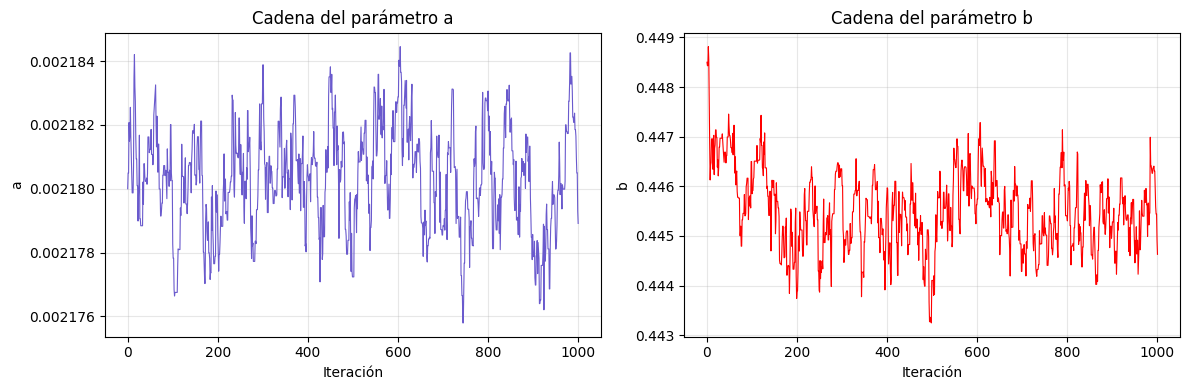

In [10]:

# Separamos los valores de a y b
a_cadena = cadena[:, 0]
b_cadena = cadena[:, 1]

# Graficamos ambas cadenas
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Cadena del parámetro a
axes[0].plot(a_cadena, color="slateblue", linewidth=0.8)
axes[0].set_title("Cadena del parámetro a")
axes[0].set_xlabel("Iteración")
axes[0].set_ylabel("a")
axes[0].grid(alpha=0.3)

# Cadena del parámetro b
axes[1].plot(b_cadena, color="red", linewidth=0.8)
axes[1].set_title("Cadena del parámetro b")
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("b")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()



### <font color="#689F38">Observación</font>

Las gráficas muestran los valores de $a$ y $b$ generados mediante Metropolis-Hastings. Cuando una propuesta es rechazada, la cadena conserva el valor anterior.

Esta primera simulación permite revisar el comportamiento de los parámetros, pero aún necesitamos comprobar la convergencia antes de calcular las estimaciones finales.



## <font color="#2E7D32">6. Análisis de convergencia</font>

Para revisar la convergencia utilizaremos el criterio de Gelman-Rubin, que compara varias cadenas generadas desde distintos estados iniciales.

El factor se define como:

$$
\hat{R}=\sqrt{\frac{\widehat{\operatorname{var}}(\theta)}{W}},
$$

donde $W$ representa la variación dentro de las cadenas y $\widehat{\operatorname{var}}(\theta)$ es la varianza estimada del parámetro.

El criterio considerado es:

$$
\boxed{0.97<\hat{R}<1.03}
$$

Aplicaremos este procedimiento a $a$ y $b$ por separado. Para ello, generaremos tres cadenas con diferentes valores iniciales y descartaremos la primera mitad de sus iteraciones.



Generaremos tres cadenas de 1000 iteraciones desde distintos valores iniciales. Utilizaremos las funciones ya definidas para evitar repetir la programación del modelo SIR y de Metropolis-Hastings.


In [11]:

# Estados iniciales de las tres cadenas
X0_valores = [
    [0.00217, 0.44],
    [0.00218, 0.45],
    [0.00219, 0.46]
]

# Número de iteraciones por cadena
n = 1000
burn_in = n // 2

# Guardamos las cadenas y sus tasas de aceptación
cadenas = []
tasas = []

for X0 in X0_valores:

    # Generamos una cadena desde cada estado inicial
    cadena_nueva, tasa = metropolis_hastings(
        X0, n, s_a, s_b
    )

    cadenas.append(cadena_nueva)
    tasas.append(tasa)

cadenas = np.array(cadenas)

# Mostramos las tasas de aceptación
for i, tasa in enumerate(tasas):
    print(f"Cadena {i+1}: {tasa:.2%} de aceptación")


Cadena 1: 70.30% de aceptación
Cadena 2: 68.60% de aceptación
Cadena 3: 65.80% de aceptación



### <font color="#689F38">6.1. Cálculo del factor de Gelman-Rubin</font>

Descartamos la primera mitad de cada cadena y calculamos el factor de Gelman-Rubin para los parámetros $a$ y $b$.

Para ello, comparamos las varianzas dentro de las cadenas con la variación entre sus medias, utilizando las expresiones:

$$
W=\frac{1}{M}\sum_{j=1}^{M}s_j^2,
\qquad
B=\frac{N_c}{M-1}\sum_{j=1}^{M}(\bar{\theta}_j-\bar{\theta})^2.
$$

La varianza estimada y el factor de convergencia son:

$$
\widehat{\operatorname{var}}(\theta)
=\left(1-\frac{1}{N_c}\right)W+\frac{B}{N_c},
$$

$$
\hat R=\sqrt{\frac{\widehat{\operatorname{var}}(\theta)}{W}}.
$$


In [12]:

# Descartamos las primeras 500 iteraciones
muestras = cadenas[:, burn_in + 1:, :]

# Función para calcular Gelman-Rubin
def gelman_rubin(valores):

    M, Nc = valores.shape

    # Varianzas dentro de las cadenas
    W = np.mean(np.var(valores, axis=1, ddof=1))

    # Variación entre las medias
    medias = np.mean(valores, axis=1)
    B = Nc * np.var(medias, ddof=1)

    # Varianza estimada
    var_theta = (1 - 1/Nc) * W + B/Nc

    return np.sqrt(var_theta / W)


# Evaluamos ambos parámetros
R_a = gelman_rubin(muestras[:, :, 0])
R_b = gelman_rubin(muestras[:, :, 1])

print(f"Gelman-Rubin para a: {R_a:.4f}")
print(f"Gelman-Rubin para b: {R_b:.4f}")

if 0.97 < R_a < 1.03 and 0.97 < R_b < 1.03:
    print("Ambos parámetros cumplen el criterio.")
else:
    print("Todavía no se cumple el criterio para ambos parámetros.")


Gelman-Rubin para a: 1.0209
Gelman-Rubin para b: 1.0047
Ambos parámetros cumplen el criterio.



### <font color="#689F38">Observación</font>

Se obtuvieron los valores $\hat R_a=1.0209$ y $\hat R_b=1.0047$. Ambos se encuentran dentro del intervalo $0.97<\hat R<1.03$, por lo que cumplen el criterio de Gelman-Rubin.

Con las muestras conservadas después del *burn-in*, calcularemos las estimaciones de $a$ y $b$ y su incertidumbre.



## <font color="#2E7D32">7. Estimación de los parámetros</font>

A partir de las muestras obtenidas mediante MCMC, calcularemos la media y la desviación estándar de cada parámetro.

También utilizaremos los percentiles 2.5 y 97.5 para obtener un intervalo del 95 %, que nos permitirá describir la incertidumbre de $a$ y $b$ bajo los supuestos utilizados en el ajuste.


In [13]:

# Reunimos las muestras de las tres cadenas
a_muestras = muestras[:, :, 0].flatten()
b_muestras = muestras[:, :, 1].flatten()

# Calculamos las medias de los parámetros
a_media = np.mean(a_muestras)
b_media = np.mean(b_muestras)

# Calculamos las desviaciones estándar
a_std = np.std(a_muestras)
b_std = np.std(b_muestras)

# Calculamos los intervalos del 95 %
IC_a = np.percentile(a_muestras, [2.5, 97.5])
IC_b = np.percentile(b_muestras, [2.5, 97.5])

# Mostramos los resultados
print(f"a = {a_media:.8f} ± {a_std:.8f}")
print(f"Intervalo 95 % de a: [{IC_a[0]:.8f}, {IC_a[1]:.8f}]")

print(f"\nb = {b_media:.6f} ± {b_std:.6f}")
print(f"Intervalo 95 % de b: [{IC_b[0]:.6f}, {IC_b[1]:.6f}]")


a = 0.00218039 ± 0.00000165
Intervalo 95 % de a: [0.00217720, 0.00218376]

b = 0.445028 ± 0.000782
Intervalo 95 % de b: [0.443526, 0.446538]



### <font color="#689F38">7.1. Distribuciones de los parámetros</font>

Para observar cómo se distribuyen los valores de $a$ y $b$, construiremos sus histogramas utilizando las muestras conservadas después del *burn-in*.

En cada gráfica señalaremos la media y los límites del intervalo del 95 %, que nos permiten visualizar la incertidumbre de los parámetros.


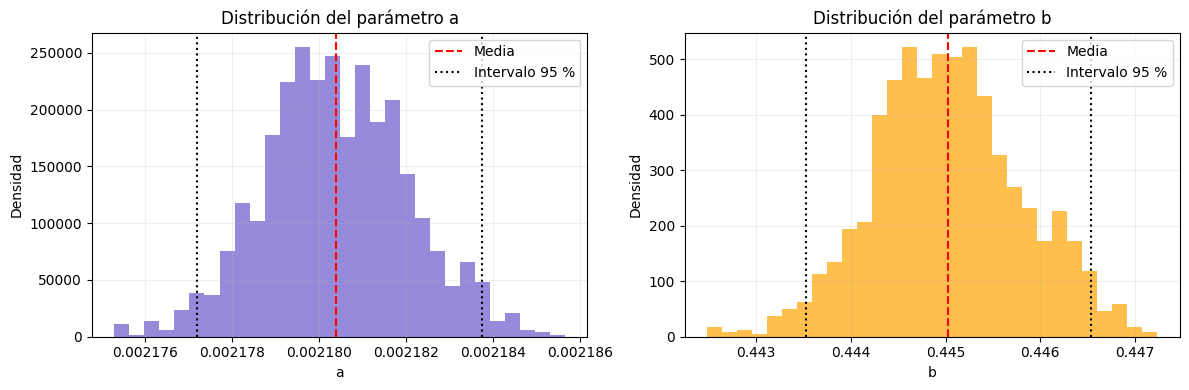

In [14]:

# Graficamos las distribuciones de a y b
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribución del parámetro a
axes[0].hist(a_muestras, bins=30, density=True,
             color="slateblue", alpha=0.7)

axes[0].axvline(a_media, color="red", linestyle="--",
                label="Media")
axes[0].axvline(IC_a[0], color="black", linestyle=":")
axes[0].axvline(IC_a[1], color="black", linestyle=":",
                label="Intervalo 95 %")

axes[0].set_title("Distribución del parámetro a")
axes[0].set_xlabel("a")
axes[0].set_ylabel("Densidad")
axes[0].legend()

# Distribución del parámetro b
axes[1].hist(b_muestras, bins=30, density=True,
             color="orange", alpha=0.7)

axes[1].axvline(b_media, color="red", linestyle="--",
                label="Media")
axes[1].axvline(IC_b[0], color="black", linestyle=":")
axes[1].axvline(IC_b[1], color="black", linestyle=":",
                label="Intervalo 95 %")

axes[1].set_title("Distribución del parámetro b")
axes[1].set_xlabel("b")
axes[1].set_ylabel("Densidad")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### <font color="#689F38">Observación</font>

Las distribuciones de $a$ y $b$ se concentran alrededor de los valores medios $0.00218039$ y $0.445028$, respectivamente.

Los intervalos del 95 % muestran la incertidumbre de los parámetros bajo el supuesto utilizado para calcular $\chi^2$.



## <font color="#2E7D32">8. Comparación del ajuste con los datos observados</font>

Con los parámetros estimados mediante MCMC, resolveremos nuevamente el modelo SIR y compararemos su solución con los datos observados.

También incluiremos las soluciones obtenidas con los parámetros de Murray y del algoritmo genético, para comparar los tres ajustes sobre el mismo conjunto de datos.


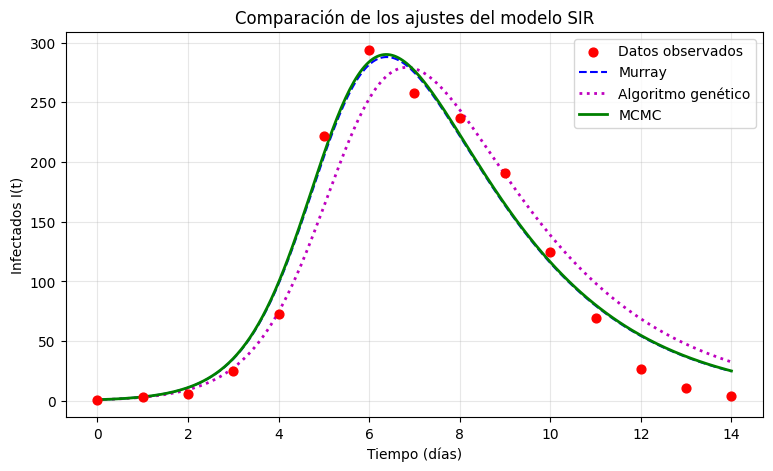

Chi-cuadrada de MCMC: 4507.13
Chi-cuadrada de Murray: 4526.49
Chi-cuadrada del GA: 10644.03


In [15]:

# Tiempo para representar las curvas suavemente
t_suave = np.linspace(0, 14, 300)

# Función para obtener los infectados en más puntos
def infectados_SIR(a, b):
    solucion = solve_ivp(
        SIR, (0, 14), [S0, I0, R0],
        args=(a, b), t_eval=t_suave,
        rtol=1e-6, atol=1e-8
    )
    if not solucion.success:
        raise RuntimeError("No se pudo resolver el modelo SIR.")
    return solucion.y[1]

# Soluciones para los tres pares de parámetros
I_Murray = infectados_SIR(a1, b1)
I_GA = infectados_SIR(a2, b2)
I_MCMC = infectados_SIR(a_media, b_media)

# Gráfica comparativa
plt.figure(figsize=(9, 5))

plt.scatter(t, I_obs, color="red", s=40,
            label="Datos observados", zorder=3)

plt.plot(t_suave, I_Murray, "b--", label="Murray")
plt.plot(t_suave, I_GA, "m:", linewidth=2,
         label="Algoritmo genético")
plt.plot(t_suave, I_MCMC, "g-", linewidth=2,
         label="MCMC")

plt.xlabel("Tiempo (días)")
plt.ylabel("Infectados I(t)")
plt.title("Comparación de los ajustes del modelo SIR")
plt.xticks(np.arange(0, 15, 2))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calculamos chi-cuadrada con los parámetros estimados
print(f"Chi-cuadrada de MCMC: {chi2(a_media, b_media):.2f}")
print(f"Chi-cuadrada de Murray: {chi2(a1, b1):.2f}")
print(f"Chi-cuadrada del GA: {chi2(a2, b2):.2f}")



### <font color="#689F38">Observación</font>

Las curvas de MCMC y Murray presentan un comportamiento muy similar y aproximan el aumento de infectados y el máximo observado alrededor del día 6. En cambio, la curva del algoritmo genético presenta un máximo ligeramente menor y desplazado hacia la derecha.

Al comparar los valores de $\chi^2$, MCMC obtuvo el menor error ($4507.13$), seguido de Murray ($4526.49$) y del algoritmo genético ($10644.03$). Sin embargo, las tres soluciones sobreestiman el número de infectados durante los últimos días.



## <font color="#2E7D32">9. Conclusión</font>

Mediante el algoritmo Metropolis-Hastings (MCMC) logramos estimar los parámetros del modelo SIR que describen el brote de influenza en el internado de 763 estudiantes.

Los valores medios obtenidos fueron:

$$
\boxed{a=0.00218039\pm0.00000165}
$$

$$
\boxed{b=0.445028\pm0.000782}
$$

Los intervalos del 95 % fueron:

$$
a\in[0.00217720,\;0.00218376]
$$

$$
b\in[0.443526,\;0.446538]
$$

Ambos parámetros cumplieron el criterio de Gelman-Rubin, con $\hat R_a=1.0209$ y $\hat R_b=1.0047$.

Con los parámetros medios estimados, obtuvimos un valor de $\chi^2=4507.13$, menor que los calculados con los parámetros de referencia de Murray y del algoritmo genético.

La solución del modelo reproduce el crecimiento y el máximo de infectados alrededor del día 6, aunque presenta diferencias durante los últimos días del brote.

Finalmente, MCMC nos permitió obtener estimaciones de $a$ y $b$ y describir su incertidumbre. Sin embargo, los intervalos calculados dependen del supuesto $\sigma_i=1$ y el valor elevado de $\chi^2$ indica que debemos interpretar esa incertidumbre con precaución.
